# SaaS Customer Churn Prediction & Retention Analysis

## Project Overview

This project analyzes SaaS subscription invoice data to understand customer churn and identify customers who may be at risk of leaving.

The original dataset contains invoice-level records. The analysis converts these records into customer-level features and uses machine learning to predict churn.

### Project Goals

- Understand the SaaS subscription dataset
- Explore customer and subscription behavior
- Define churn using a time-based approach
- Build customer-level features
- Compare Logistic Regression, Decision Tree, and Random Forest models
- Identify the most important churn-related features
- Rank high-risk customers for retention analysis


## Table of Contents

1. [Data Loading](#1-data-loading)
2. [Data Understanding](#2-data-understanding)
3. [Churn Definition](#3-churn-definition)
4. [Exploratory Churn Analysis](#4-exploratory-churn-analysis)
5. [Feature Engineering](#5-feature-engineering)
6. [Machine Learning](#6-machine-learning)
7. [Model Comparison](#7-model-comparison)
8. [High-Risk Customer Identification](#8-high-risk-customer-identification)
9. [Business Insights & Recommendations](#9-business-insights--recommendations)
10. [Final Conclusion](#10-final-conclusion)


# 1. Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    cross_validate,
    cross_val_predict
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [2]:
excel_file=pd.ExcelFile('saas-subscriptions-v1.0.0-analysis.xlsx')
excel_file.sheet_names


['SaaS Subscriptions & Customer C']

In [3]:
df = pd.read_excel(
    excel_file,
    sheet_name="SaaS Subscriptions & Customer C"
)

df["invoice_date"] = pd.to_datetime(df["invoice_date"])

print(df.head())


   invoice_id invoice_date invoice_status account_id region segment  \
0  INV0000001   2024-06-11           paid    A000001  LATAM     SMB   
1  INV0000002   2024-07-11           paid    A000001  LATAM     SMB   
2  INV0000003   2024-08-11           paid    A000001  LATAM     SMB   
3  INV0000004   2024-09-11           paid    A000001  LATAM     SMB   
4  INV0000005   2024-10-11           paid    A000001  LATAM     SMB   

  subscription_id plan_name  seats    mrr  amount_due  amount_paid  
0         S000001    Growth     13  199.0       199.0        199.0  
1         S000001    Growth     13  199.0       199.0        199.0  
2         S000001    Growth     13  199.0       199.0        199.0  
3         S000001    Growth     13  199.0       199.0        199.0  
4         S000001    Growth     13  199.0       199.0        199.0  


# 2. Data Understanding

In [4]:
print(df.info())
print(df.isnull().sum())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85448 entries, 0 to 85447
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   invoice_id       85448 non-null  object        
 1   invoice_date     85448 non-null  datetime64[ns]
 2   invoice_status   85448 non-null  object        
 3   account_id       85448 non-null  object        
 4   region           63830 non-null  object        
 5   segment          85448 non-null  object        
 6   subscription_id  85448 non-null  object        
 7   plan_name        85448 non-null  object        
 8   seats            85448 non-null  int64         
 9   mrr              85448 non-null  float64       
 10  amount_due       85448 non-null  float64       
 11  amount_paid      85448 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(7)
memory usage: 7.8+ MB
None
invoice_id             0
invoice_date           0
invoice_statu

### Checking the dataset structure

Before building the churn model, we first inspect the dataset, missing values, and descriptive statistics.

Check the categories

### Checking the main categories

The dataset contains information about invoice status, subscription plans, regions, and customer segments. These categorical variables can later be used as model features.


### 1. What payment statuses exist?

In [5]:
print(df['invoice_status'].value_counts())

invoice_status
paid    80101
open     5311
void       36
Name: count, dtype: int64


### 2. What subscription plans do customers have?

In [6]:
print(df['plan_name'].value_counts())

plan_name
Starter       41551
Growth        27497
Scale         11605
Enterprise     4795
Name: count, dtype: int64


### 3. Which regions exist, and how many are missing?

In [7]:
print(df['region'].value_counts())

region
EMEA     21890
LATAM    21234
APAC     20706
Name: count, dtype: int64


### 4. What types of customers exist?

In [8]:
print(df['segment'].value_counts())


segment
SMB           60277
mid_market    19998
enterprise     5173
Name: count, dtype: int64


In [9]:
# Dataset time coverage
print("Start date:", df["invoice_date"].min())
print("End date:", df["invoice_date"].max())


Start date: 2023-01-04 00:00:00
End date: 2025-12-28 00:00:00


In [10]:
print("Unique customers:", df["account_id"].nunique())


Unique customers: 5000


In [11]:
print("Unique subscriptions:", df["subscription_id"].nunique())


Unique subscriptions: 5000


# 3. Churn Definition

A reliable churn model needs a clear prediction point.

For this project:

- **Cutoff date:** July 1, 2025
- **Active window:** 60 days before the cutoff
- **Future observation window:** 90 days after the cutoff
- A customer is considered **churned** when they were active before the cutoff but had no invoice activity during the following 90 days.

This approach keeps future behavior separate from the features used for prediction.


In [12]:
cutoff_date = pd.Timestamp("2025-07-01")
print("Cutoff date:", cutoff_date)


Cutoff date: 2025-07-01 00:00:00


In [13]:
past_df = df[df["invoice_date"] < cutoff_date].copy()
print("Past data shape:", past_df.shape)


Past data shape: (61145, 12)


In [14]:
future_df = df[df["invoice_date"] >= cutoff_date].copy()
print("Future data shape:", future_df.shape)


Future data shape: (24303, 12)


In [15]:
active_window_start = cutoff_date - pd.Timedelta(days=60)
print("Active window starts:", active_window_start)


Active window starts: 2025-05-02 00:00:00


In [16]:
active_customers = past_df[
    past_df["invoice_date"] >= active_window_start
]["account_id"].unique()

print("Active customers:", len(active_customers))


Active customers: 3798


In [17]:
future_end = cutoff_date + pd.Timedelta(days=90)
print("Future observation window ends:", future_end)


Future observation window ends: 2025-09-29 00:00:00


In [18]:
future_active_customers = future_df[
    future_df["invoice_date"] < future_end
]["account_id"].unique()

print("Customers with future activity:", len(future_active_customers))


Customers with future activity: 4186


In [19]:
future_active_cohort = (
    set(active_customers) & set(future_active_customers)
)

print("Customers who continued:", len(future_active_cohort))


Customers who continued: 3716


In [20]:
churned_customers = (
    set(active_customers) - set(future_active_customers)
)

print("Churned customers:", len(churned_customers))


Churned customers: 82


### Finding

The prediction cohort contains **3,798 active customers**. Of these, **82 customers churned** during the 90-day future observation window.

This gives an observed churn rate of approximately **2.16%** in the modeling cohort, so the dataset is highly imbalanced.


# 4. Exploratory Churn Analysis

### Building the customer-level modeling dataset

Only invoice information available before the cutoff date is used to create the prediction features.


In [21]:
model_df = past_df[
    past_df["account_id"].isin(active_customers)
].copy()

print("Modeling data shape:", model_df.shape)


Modeling data shape: (53846, 12)


In [22]:
customer_model = model_df.groupby("account_id").agg(
    first_invoice_date=("invoice_date", "min"),
    last_invoice_date=("invoice_date", "max"),
    invoice_count=("invoice_id", "count"),
    total_mrr=("mrr", "sum"),
    avg_mrr=("mrr", "mean"),
    total_amount_paid=("amount_paid", "sum"),
    avg_amount_paid=("amount_paid", "mean"),
    total_seats=("seats", "sum"),
    avg_seats=("seats", "mean")
).reset_index()

print(customer_model.shape)


(3798, 10)


In [23]:
customer_model["days_inactive_at_cutoff"] = (
    cutoff_date - customer_model["last_invoice_date"]
).dt.days

print(
    customer_model[
        ["account_id", "last_invoice_date", "days_inactive_at_cutoff"]
    ].head()
)


  account_id last_invoice_date  days_inactive_at_cutoff
0    A000001        2025-06-11                       20
1    A000002        2025-06-07                       24
2    A000003        2025-06-24                        7
3    A000004        2025-06-14                       17
4    A000006        2025-06-25                        6


In [24]:
customer_info_model = model_df.groupby("account_id").agg(
    plan_name=("plan_name", "last"),
    region=("region", "last"),
    segment=("segment", "last")
).reset_index()

customer_model = customer_model.merge(
    customer_info_model,
    on="account_id",
    how="left"
)

print(customer_model.shape)


(3798, 14)


In [25]:
customer_model["tenure"] = (
    cutoff_date - customer_model["first_invoice_date"]
).dt.days

customer_model[
    ["account_id", "first_invoice_date", "tenure"]
].head()


,account_id,first_invoice_date,tenure
0,A000001,2024-06-11,385
1,A000002,2025-04-07,85
2,A000003,2024-07-24,342
3,A000004,2024-01-14,534
4,A000006,2024-08-25,310


In [26]:
print(customer_model.isna().sum())


account_id                   0
first_invoice_date           0
last_invoice_date            0
invoice_count                0
total_mrr                    0
avg_mrr                      0
total_amount_paid            0
avg_amount_paid              0
total_seats                  0
avg_seats                    0
days_inactive_at_cutoff      0
plan_name                    0
region                     942
segment                      0
tenure                       0
dtype: int64


In [27]:
customer_model["region"] = customer_model["region"].fillna("unknown")
customer_model["region"].value_counts()


region
LATAM      963
EMEA       953
unknown    942
APAC       940
Name: count, dtype: int64

In [28]:
customer_model["churn"] = (
    customer_model["account_id"]
    .isin(churned_customers)
    .astype(int)
)

print(customer_model["churn"].value_counts())


churn
0    3716
1      82
Name: count, dtype: int64


### Churn rate by subscription plan

In [29]:
plan_churn = (
    customer_model.groupby("plan_name")["churn"]
    .mean()
    .mul(100)
    .reset_index(name="churn_rate")
)

print(plan_churn)


    plan_name  churn_rate
0  Enterprise    2.926829
1      Growth    2.103560
2       Scale    2.321083
3     Starter    2.065217


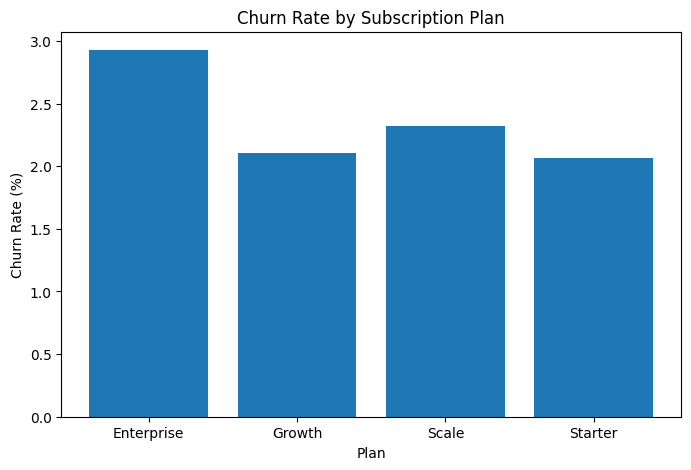

In [30]:
plt.figure(figsize=(8, 5))

plt.bar(
    plan_churn["plan_name"],
    plan_churn["churn_rate"]
)

plt.xlabel("Plan")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Subscription Plan")
plt.show()


**Finding:** The observed churn rates are relatively close across subscription plans. Enterprise has the highest observed rate in this cohort, while Starter has the lowest. These are descriptive differences and do not establish that plan type causes churn.


### Customer inactivity and churn

In [31]:
inactivity_churn = (
    customer_model.groupby("churn")["days_inactive_at_cutoff"]
    .mean()
    .reset_index()
)

inactivity_churn["status"] = inactivity_churn["churn"].map({
    0: "Retained",
    1: "Churned"
})

inactivity_churn


,churn,days_inactive_at_cutoff,status
0,0,15.124327,Retained
1,1,34.682927,Churned


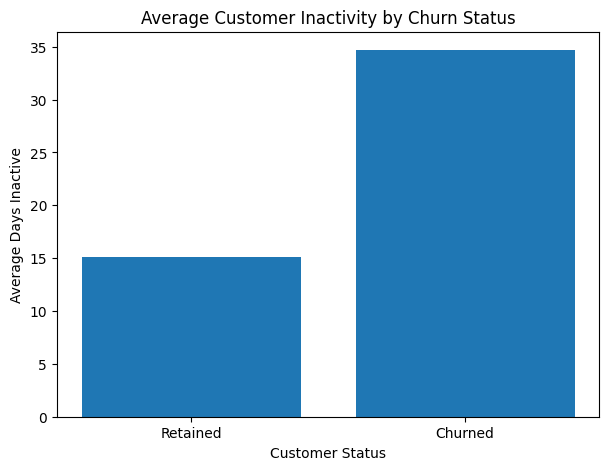

In [32]:
plt.figure(figsize=(7, 5))

plt.bar(
    inactivity_churn["status"],
    inactivity_churn["days_inactive_at_cutoff"]
)

plt.xlabel("Customer Status")
plt.ylabel("Average Days Inactive")
plt.title("Average Customer Inactivity by Churn Status")
plt.show()


**Finding:** Customers who eventually churned had substantially more days of inactivity at the cutoff than retained customers. This makes inactivity an important early-warning signal in this dataset.


### Overall churn summary

In [33]:
total_customers = len(customer_model)
churned_customers_count = customer_model["churn"].sum()
overall_churn_rate = customer_model["churn"].mean() * 100

print("Total customers:", total_customers)
print("Churned customers:", churned_customers_count)
print("Overall churn rate:", round(overall_churn_rate, 2), "%")

Total customers: 3798
Churned customers: 82
Overall churn rate: 2.16 %


**Finding:** The cohort contains 3,798 customers and 82 churn cases, producing an overall churn rate of approximately 2.16%.

Because the churn class is small, accuracy alone is not a sufficient model evaluation metric.


# 5. Feature Engineering

The invoice-level data is converted into one row per customer.

### Features used

- Invoice count
- Tenure
- Total MRR
- Average MRR
- Total amount paid
- Average amount paid
- Total seats
- Average seats
- Days inactive at cutoff
- Plan
- Region
- Segment


In [34]:
features = [
    "invoice_count",
    "tenure",
    "total_mrr",
    "avg_mrr",
    "total_amount_paid",
    "avg_amount_paid",
    "total_seats",
    "avg_seats",
    "days_inactive_at_cutoff",
    "plan_name",
    "region",
    "segment"
]

X = customer_model[features]
y = customer_model["churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (3798, 12)
y shape: (3798,)


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=42,
    test_size=0.2,
    stratify=y
)

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)


Training data: (3038, 12)
Test data: (760, 12)


In [36]:
categorical_features = [
    "plan_name",
    "region",
    "segment"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)


### Why use a preprocessing pipeline?

The categorical columns must be converted into numerical values before training. `OneHotEncoder` handles this conversion.

`handle_unknown="ignore"` prevents errors if a category appears in the test data that was not present during training.

The preprocessing step is placed inside each model's pipeline so that the transformation is learned separately inside each training fold during cross-validation.


# 6. Machine Learning

Three classification models are tested:

1. Logistic Regression
2. Decision Tree
3. Random Forest

Because churn is much less common than retention, `class_weight="balanced"` is used to give additional importance to the minority churn class.


In [37]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]
)

logistic_model.fit(X_train, y_train)


c:\Users\ahame\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers cont

In [38]:
logistic_pred = logistic_model.predict(X_test)
print(logistic_pred[:10])


[0 1 1 1 1 0 0 0 0 0]


In [39]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, logistic_pred))

print("\nClassification Report:")
print(classification_report(y_test, logistic_pred, zero_division=0))


Confusion Matrix:
[[578 166]
 [  3  13]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.78      0.87       744
           1       0.07      0.81      0.13        16

    accuracy                           0.78       760
   macro avg       0.53      0.79      0.50       760
weighted avg       0.98      0.78      0.86       760



### Logistic Regression — Finding

Logistic Regression catches a large proportion of the churn cases, but it also produces a relatively high number of false positives. This is a common trade-off when class weights are used to improve minority-class recall.


#### 2. Decision Tree

In [40]:
tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=5,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

tree_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers cont

In [41]:
tree_pred = tree_model.predict(X_test)


In [42]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, tree_pred))

print("\nClassification Report:")
print(classification_report(y_test, tree_pred, zero_division=0))


Confusion Matrix:
[[716  28]
 [  4  12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.98       744
           1       0.30      0.75      0.43        16

    accuracy                           0.96       760
   macro avg       0.65      0.86      0.70       760
weighted avg       0.98      0.96      0.97       760



### Decision Tree — Finding

The Decision Tree gives a stronger balance between precision and recall than Logistic Regression on the held-out test set. Its maximum depth is limited to 5 to reduce unnecessary complexity.


#### 3. Random Forest

In [43]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ))
    ]
)

rf_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers cont

In [44]:
rf_pred = rf_model.predict(X_test)


In [45]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))


Confusion Matrix:
[[743   1]
 [  5  11]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       744
           1       0.92      0.69      0.79        16

    accuracy                           0.99       760
   macro avg       0.95      0.84      0.89       760
weighted avg       0.99      0.99      0.99       760



### Random Forest — Finding

The Random Forest performs extremely strongly on the single held-out test split. However, because only 82 customers are in the churn class, a single split can be misleading.

For that reason, cross-validation is used before drawing conclusions about model performance.


# 7. Model Comparison

### 5-Fold Cross-Validation

The models are compared using precision, recall, and F1-score for the churn class.

F1-score is especially useful here because the churn class is imbalanced and we want to balance finding churners with avoiding excessive false alarms.


In [46]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Random Forest": rf_model
}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="f1"
    )

    print(name)
    print("F1 scores:", scores)
    print("Mean F1:", round(scores.mean(), 3))
    print()


c:\Users\ahame\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\ahame\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please als

Logistic Regression
F1 scores: [0.12807882 0.14444444 0.13592233 0.11363636 0.11464968]
Mean F1: 0.127

Decision Tree
F1 scores: [0.61111111 0.41666667 0.78787879 0.26865672 0.33333333]
Mean F1: 0.484

Random Forest
F1 scores: [0.81481481 0.69230769 0.78787879 0.66666667 0.60869565]
Mean F1: 0.714



In [47]:
for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=5,
        scoring=["precision", "recall", "f1"]
    )

    print(name)
    print("Mean Precision:", round(scores["test_precision"].mean(), 3))
    print("Mean Recall:", round(scores["test_recall"].mean(), 3))
    print("Mean F1:", round(scores["test_f1"].mean(), 3))
    print()


c:\Users\ahame\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\ahame\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please als

Logistic Regression
Mean Precision: 0.07
Mean Recall: 0.718
Mean F1: 0.127

Decision Tree
Mean Precision: 0.422
Mean Recall: 0.621
Mean F1: 0.484

Random Forest
Mean Precision: 0.962
Mean Recall: 0.584
Mean F1: 0.714



### Model Comparison — Finding

Across 5-fold cross-validation, Random Forest has the highest mean F1-score, with Decision Tree close behind. Logistic Regression has substantially lower F1 performance on the churn class.

The cross-validation scores also vary across folds because the dataset contains only 82 churn cases. Therefore, the Random Forest should be described as the strongest model **in this experiment**, rather than as a perfect or production-ready model.


### Random Forest Confusion Matrix

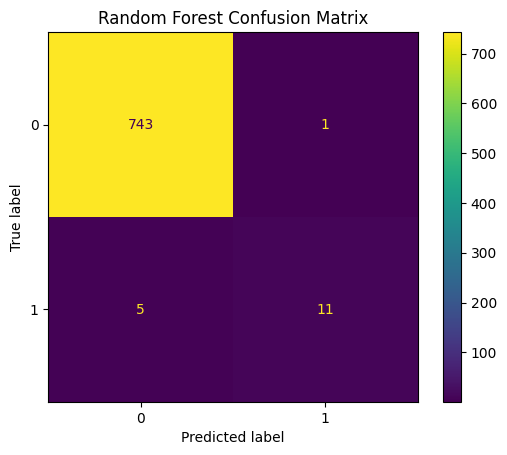

In [48]:
ConfusionMatrixDisplay.from_estimator(
    rf_model,
    X_test,
    y_test
)

plt.title("Random Forest Confusion Matrix")
plt.show()


### Random Forest Feature Importance

In [49]:
# Feature importance
rf_classifier = rf_model.named_steps["classifier"]


In [50]:
feature_names = (
    rf_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_names

array(['cat__plan_name_Enterprise', 'cat__plan_name_Growth',
       'cat__plan_name_Scale', 'cat__plan_name_Starter',
       'cat__region_APAC', 'cat__region_EMEA', 'cat__region_LATAM',
       'cat__region_unknown', 'cat__segment_SMB',
       'cat__segment_enterprise', 'cat__segment_mid_market',
       'remainder__invoice_count', 'remainder__tenure',
       'remainder__total_mrr', 'remainder__avg_mrr',
       'remainder__total_amount_paid', 'remainder__avg_amount_paid',
       'remainder__total_seats', 'remainder__avg_seats',
       'remainder__days_inactive_at_cutoff'], dtype=object)

In [51]:
feature_names = (
    rf_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_classifier.feature_importances_
})

feature_importance["feature"] = (
    feature_importance["feature"]
    .str.replace("cat__", "", regex=False)
    .str.replace("remainder__", "", regex=False)
)

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

print(feature_importance)


                    feature  importance
19  days_inactive_at_cutoff    0.399524
12                   tenure    0.118718
11            invoice_count    0.091531
17              total_seats    0.076041
15        total_amount_paid    0.066383
13                total_mrr    0.062912
18                avg_seats    0.051930
16          avg_amount_paid    0.045247
14                  avg_mrr    0.014621
6              region_LATAM    0.014454
10       segment_mid_market    0.014343
4               region_APAC    0.009114
5               region_EMEA    0.009113
8               segment_SMB    0.008926
7            region_unknown    0.008045
1          plan_name_Growth    0.003403
3         plan_name_Starter    0.002795
9        segment_enterprise    0.001412
2           plan_name_Scale    0.000987
0      plan_name_Enterprise    0.000502


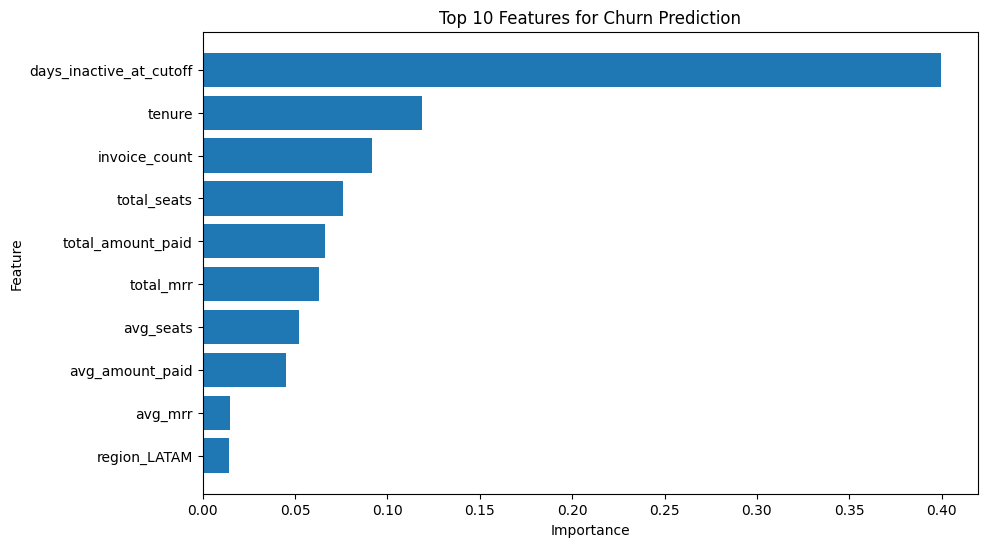

In [52]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features for Churn Prediction")
plt.show()


### Feature Importance — Finding

`days_inactive_at_cutoff` is the strongest feature in the Random Forest. Tenure, seats, invoice activity, and financial features also contribute to the model.

Feature importance shows which variables the model relied on; it does **not** prove that those variables cause churn.


# 8. High-Risk Customer Identification

A retention team may not have resources to contact every customer. Therefore, the model can be used to rank customers by predicted churn probability.

To avoid using predictions generated from a model trained on the same customer, **out-of-fold probabilities** are used.


In [53]:
oof_probabilities = cross_val_predict(
    rf_model,
    X,
    y,
    cv=5,
    method="predict_proba"
)[:, 1]


In [54]:
customer_predictions = customer_model[
    ["account_id", "plan_name", "region", "segment", "days_inactive_at_cutoff"]
].copy()

customer_predictions["churn_probability"] = oof_probabilities

customer_predictions = customer_predictions.sort_values(
    "churn_probability",
    ascending=False
)

customer_predictions.head(10)


,account_id,plan_name,region,segment,days_inactive_at_cutoff,churn_probability
1317,A001738,Growth,LATAM,SMB,56,0.909771
1074,A001427,Growth,EMEA,SMB,56,0.885906
112,A000144,Growth,unknown,SMB,56,0.880069
1480,A001956,Starter,APAC,SMB,47,0.878265
511,A000682,Growth,unknown,SMB,36,0.870550
951,A001257,Growth,APAC,SMB,59,0.861767
3102,A004102,Starter,LATAM,SMB,41,0.859568
3339,A004410,Growth,unknown,SMB,34,0.858976
2765,A003645,Starter,unknown,SMB,46,0.856384
2651,A003498,Starter,EMEA,SMB,41,0.853785


In [55]:
top_10 = customer_predictions.head(10).copy()

top_10 = top_10.merge(
    customer_model[["account_id", "churn"]],
    on="account_id",
    how="left"
)

print(top_10)


  account_id plan_name   region segment  days_inactive_at_cutoff  \
0    A001738    Growth    LATAM     SMB                       56   
1    A001427    Growth     EMEA     SMB                       56   
2    A000144    Growth  unknown     SMB                       56   
3    A001956   Starter     APAC     SMB                       47   
4    A000682    Growth  unknown     SMB                       36   
5    A001257    Growth     APAC     SMB                       59   
6    A004102   Starter    LATAM     SMB                       41   
7    A004410    Growth  unknown     SMB                       34   
8    A003645   Starter  unknown     SMB                       46   
9    A003498   Starter     EMEA     SMB                       41   

   churn_probability  churn  
0           0.909771      1  
1           0.885906      1  
2           0.880069      1  
3           0.878265      1  
4           0.870550      1  
5           0.861767      1  
6           0.859568      1  
7          

In [56]:
top_10_precision = top_10["churn"].mean()
top_10_recall = (
    top_10["churn"].sum()
    / customer_model["churn"].sum()
)

print("Precision@10:", round(top_10_precision * 100, 2), "%")
print("Recall@10:", round(top_10_recall * 100, 2), "%")


Precision@10: 100.0 %
Recall@10: 12.2 %


### High-Risk Customer Finding

The out-of-fold ranking places several customers who later churned near the top of the risk list. This demonstrates how the model can be used to **prioritize a small group of customers for retention analysis**.

Precision@10 measures how many of the top 10 ranked customers actually churned. Recall@10 measures how many of all churned customers were captured in those top 10.

These metrics describe this specific cohort and should not be treated as a guarantee for future customers.


# 9. Business Insights & Recommendations

### Business Insight 1 — Inactivity is an important warning signal

Customers who eventually churned were considerably more inactive at the prediction cutoff than retained customers.

**Recommendation:** Build an early-warning process that flags customers whose invoice activity is declining or has stopped.

### Business Insight 2 — Churn is an imbalanced business problem

Only a small portion of the modeling cohort churned.

**Recommendation:** Evaluate churn models using precision, recall, and F1-score rather than relying only on accuracy.

### Business Insight 3 — Retention resources can be prioritized

The model can rank customers by predicted churn probability.

**Recommendation:** Use the risk ranking to prioritize retention outreach when the business has limited customer-success resources.

### Business Insight 4 — Customer value should also be considered

The observed churned group was not simply the lowest-value group in this cohort.

**Recommendation:** Combine churn risk with customer value when deciding which accounts deserve additional retention attention. This is a prioritization strategy, not evidence that customer value causes churn.


# 10. Final Conclusion

This project demonstrates an end-to-end SaaS churn prediction workflow:

**Invoice Data → Data Understanding → Time-Based Churn Definition → Customer Feature Engineering → Exploratory Analysis → Machine Learning → Cross-Validation → Feature Importance → High-Risk Customer Ranking**

### Key Results

- **3,798** customers were included in the prediction cohort.
- **82** customers churned during the 90-day future observation window.
- The observed churn rate was approximately **2.16%**.
- Customer inactivity at the cutoff was the most important Random Forest feature.
- Random Forest achieved the highest mean F1-score among the three tested models in 5-fold cross-validation.
- Out-of-fold churn probabilities were used to create a high-risk customer ranking.

### Final Note

The dataset is useful for demonstrating a complete data science workflow, but the relatively small number of churn cases means model performance is uncertain. A production system would require more historical cohorts, continuous validation, and monitoring after deployment.
